<a href="https://colab.research.google.com/github/nilesh-r-dev/TNS_T170800502_AIML/blob/main/tns_day_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Building Neural Networks with TensorFlow/Keras

---

## Theory

**TensorFlow** is an open-source machine learning library developed by Google that allows building and training deep learning models efficiently.  

**Keras** is a high-level API integrated with TensorFlow that simplifies the process of building neural networks by providing easy-to-use abstractions for layers, models, and training routines.

---

### Key Concepts

1. **Sequential API:**  
   Used for creating models layer-by-layer in a linear stack. Ideal for simple feedforward networks.

2. **Functional API:**  
   Allows building complex models with multiple inputs, outputs, or shared layers.

3. **Layers:**  
   Neural networks are built by stacking layers such as:
   - `Dense` (fully connected layer)
   - `Conv2D` (convolutional layer for images)
   - `LSTM` (for sequential data)
   - Activation functions can be applied via `activation` parameter or separate layers.

4. **Compiling the Model:**  
   Before training, a model is compiled with:
   - **Optimizer:** Method to update weights (`SGD`, `Adam`, etc.)
   - **Loss Function:** Guides the training (`mse`, `binary_crossentropy`, `categorical_crossentropy`, etc.)
   - **Metrics:** To monitor performance (`accuracy`, `mae`, etc.)

5. **Training the Model:**  
   Done using `model.fit()` with:
   - Training data (`X_train`, `y_train`)
   - Number of epochs (iterations over the dataset)
   - Batch size (number of samples per weight update)
   - Validation data (optional) to monitor performance on unseen data.

6. **Evaluating and Predicting:**  
   - `model.evaluate()` to check loss and metrics on test data.
   - `model.predict()` to make predictions on new data.

---

### Workflow Summary

1. Prepare dataset and preprocess.  
2. Build the model using Sequential or Functional API.  
3. Compile the model with optimizer, loss, and metrics.  
4. Train the model with `fit()`.  
5. Evaluate on test data.  
6. Make predictions with `predict()`.  
7. (Optional) Visualize training history (loss/accuracy curves).  


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.3646 - loss: 1.5106 - val_accuracy: 0.3750 - val_loss: 1.3023
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5833 - loss: 1.3876 - val_accuracy: 0.7083 - val_loss: 1.1854
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6458 - loss: 1.2705 - val_accuracy: 0.7083 - val_loss: 1.0924
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6458 - loss: 1.1738 - val_accuracy: 0.7083 - val_loss: 1.0094
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6458 - loss: 1.0738 - val_accuracy: 0.7083 - val_loss: 0.9387
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6458 - loss: 0.9908 - val_accuracy: 0.7083 - val_loss: 0.8682
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6458 - loss: 0.9240 - val_accuracy: 0.7083 - val_loss: 0.8283
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6458 - loss: 0.8744 - val_accuracy: 0.7083 - val_loss

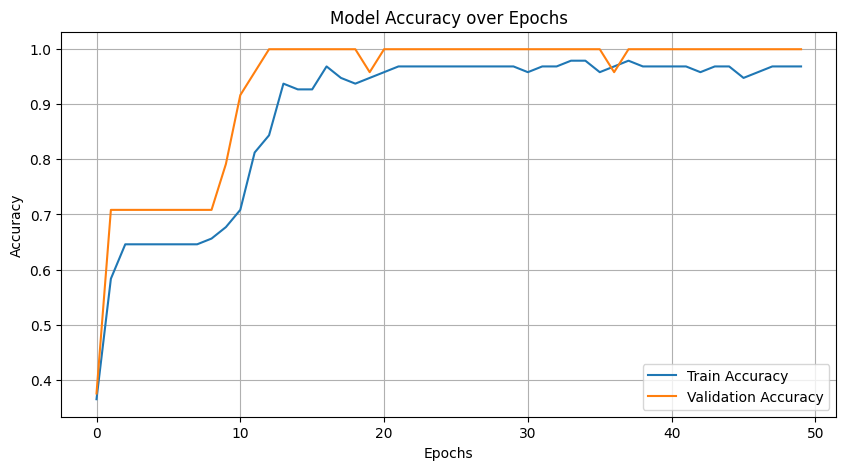

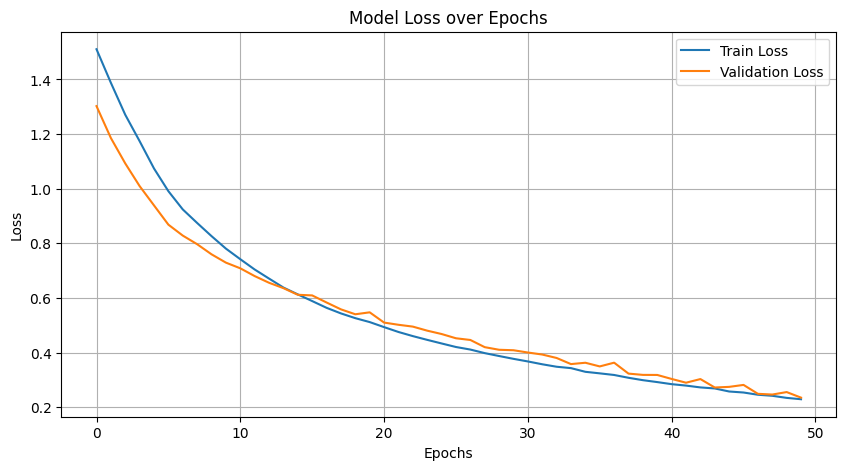

In [1]:
# ==============================
# Building Neural Networks with TensorFlow/Keras
# ==============================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt

# 1. Load dataset (Iris dataset)
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# 2. One-hot encode target
encoder = OneHotEncoder(sparse_output=False)  # updated for latest sklearn
y_encoded = encoder.fit_transform(y)

# 3. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

# 4. Build Neural Network (Sequential API)
model = Sequential([
    Dense(10, input_shape=(X.shape[1],), activation='relu'),  # Hidden layer
    Dense(8, activation='relu'),                               # Hidden layer
    Dense(y_encoded.shape[1], activation='softmax')           # Output layer
])

# 5. Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 6. Train the model
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=8,
    verbose=1
)

# 7. Evaluate the model on test data
loss, accuracy = model.evaluate(X_test, y_test)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# 8. Plot training history
plt.figure(figsize=(10,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model Accuracy over Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Model Loss over Epochs')
plt.legend()
plt.grid(True)
plt.show()


# **Unsupervised K-Mean : **


🤖 What is K-Means Clustering?
K-Means is an Unsupervised Machine Learning algorithm.
What does "Unsupervised" mean?
Supervised Learning → We already know the correct answer (target column).
Example: Predict whether an email is Spam or Not Spam.
Unsupervised Learning → We don't have any target/output column.
The algorithm finds patterns on its own.

Real-Life Example
Imagine you own a shopping mall.
100 customers visit your mall.
You only know:
Age
Income
Annual Spending
You don't know which customer belongs to which category.
K-Means automatically groups similar customers.
For example:
Cluster 1
Young
Low income
Low spending
Cluster 2
Middle age
High income
High spending
Cluster 3
Senior citizens
Medium income
Medium spending
You never told the algorithm these groups—it found them itself.

What is a Cluster?
A cluster is simply a group of similar data points.
Example:
Suppose you have marks:
35
38
40
42

75
78
80
82

95
96
98
99
K-Means will naturally make:
Cluster 1 → Low marks
Cluster 2 → Average marks
Cluster 3 → High marks

What does K mean?
K is simply:
Number of clusters (groups)
Example:
K = 2
The algorithm makes 2 groups.
K = 3
The algorithm makes 3 groups.
K = 5
The algorithm makes 5 groups.

Goal of K-Means
The algorithm wants to:
✅ Keep similar data points together.
✅ Keep different groups far apart.
Think of a classroom.
Good grouping:
Group A
20
22
21
23

Group B
80
82
81
79
Bad grouping:
20
80
21
79
22
82
The first grouping makes much more sense.

How K-Means Works
Imagine these points:
10
12
15

70
72
75

95
97
99
Suppose
K = 3

Step 1
Choose K
K = 3
Meaning:
Make 3 groups.

Step 2
Randomly place 3 centroids.
A centroid is the center point of a cluster.
Example:
Centroid A

Centroid B

Centroid C
Initially they are placed randomly.

Step 3
Every point goes to its nearest centroid.
Example:
10 → A

12 → A

15 → A

70 → B

72 → B

75 → B

95 → C

97 → C

99 → C

Step 4
Now calculate a new center.
Example
Cluster:
10
12
15
New centroid becomes approximately:
12.3

Step 5
Again assign points to the nearest centroid.
Again update the centroid.
Repeat.
Repeat.
Repeat.
Eventually, nothing changes.
This is called convergence.

What is a Centroid?
Centroid means:
Center of a cluster.
Example
Cluster:
20
22
25
23
Center is around
22.5
That becomes the centroid.
Think of it as the average location of all points in that cluster.

What is Inertia?
This is one of the most important concepts.
Inertia measures:
How close data points are to their centroid.
Small distance = Good clustering.
Large distance = Bad clustering.
Example:
Good Cluster
20
21
22
23
24
Centroid:
22
All points are close.
Inertia is low.

Bad Cluster
20

45

90

120
Centroid:
68
Everyone is far away.
Inertia is high.
Easy way to remember:
Low inertia = Better clusters
High inertia = Poor clusters

Why do we need the best K?
Suppose there are actually 3 natural groups in your data.
If K = 2
Students

Low Marks

High + Medium Marks
Different groups get merged.

If K = 5
Low

Low-High

Medium-Low

Medium-High

High
One natural group gets split unnecessarily.
So choosing the right K is very important.

Elbow Method
This helps us find the best value of K.
We train K-Means many times.
K = 1

K = 2

K = 3

K = 4

K = 5

K = 6
For every K, we calculate the inertia.
Example:
K
Inertia
1
1000
2
600
3
300
4
250
5
230
6
220

Notice:
From 1 → 2 → 3, inertia drops a lot.
After K = 3, it decreases only a little.
This means K = 3 is probably the best choice.
If you plot these values, the graph bends like an elbow (your arm), and that bend is chosen as the optimal K.

Silhouette Score
The Elbow Method is visual and sometimes the bend is not very clear.
The Silhouette Score gives a numerical value to tell how good the clustering is.
It checks two things:
Are points close to others in the same cluster?
Are they far from points in other clusters?
Its value ranges from -1 to 1:
Close to 1 → Excellent clustering ✅
Around 0 → Clusters overlap ⚠️
Less than 0 → Wrong clustering ❌
So if:
K
Silhouette Score
2
0.42
3
0.68
4
0.55

Then K = 3 is the better choice because it has the highest score.

Quick Interview Revision
K-Means: Unsupervised algorithm that groups similar data into K clusters.
Cluster: A group of similar data points.
K: Number of clusters.
Centroid: The center point (average position) of a cluster.
Inertia: Total distance of points from their centroid. Lower is better.
Elbow Method: Finds the optimal K by looking for the "elbow" in the inertia graph.
Silhouette Score: Measures clustering quality; values closer to 1 indicate better-separated clusters.
















Step 1: Create an empty list
inertia_values = []
Creates an empty list.
This list will store the inertia value for each K.
Example:
Initially:
inertia_values = []
Later it might become:
inertia_values = [1000, 650, 420, 350, 300]

Step 2: Define the range of K values
K_range = range(1, 11)
This means:
1, 2, 3, 4, 5, 6, 7, 8, 9, 10
The algorithm will test 10 different values of K.
Instead of trying only:
K = 3
it tries:
K = 1
K = 2
K = 3
...
K = 10
to find the best one.

Step 3: Loop through each K
for k in K_range:
The loop starts.
First iteration:
k = 1
Second:
k = 2
Third:
k = 3
...
Last:
k = 10

Step 4: Create the K-Means model
kmeans = KMeans(
    n_clusters=k,
    init='k-means++',
    random_state=42
)
Here we create the K-Means algorithm.
n_clusters=k
Means:
Create k clusters.
If
k = 3
then
n_clusters = 3
The algorithm will divide the data into 3 groups.

init='k-means++'
This decides how the initial centroids are chosen.
Remember:
K-Means first places centroids randomly.
Instead of completely random, k-means++ chooses better starting points.
Why?
Because better starting centroids usually lead to:
Better clustering
Faster convergence
Simple answer for class/interview:
k-means++ selects smart initial centroids to improve clustering accuracy.

random_state=42
Makes the results repeatable.
Without it:
Every time you run the code, you may get slightly different clusters.
With
random_state=42
you get the same output every time.
Simple answer:
random_state fixes the randomness so results are reproducible.

Step 5: Train the model
kmeans.fit(scaled_data)
Here the algorithm starts learning.
It:
Chooses centroids
Assigns data points
Updates centroids
Repeats until convergence
All of this happens automatically.
Think of .fit() as:
Train the model using the given data.

Step 6: Store the inertia
inertia_values.append(kmeans.inertia_)
After training,
K-Means calculates the inertia.
Remember:
Inertia = Sum of squared distances of all points from their nearest centroid.
Then we store it.
Example:
When
K = 1
Inertia may be
1000
List becomes
[1000]
Next
K = 2
Inertia becomes
650
List becomes
[1000, 650]
Next
K = 3
Inertia becomes
420
List becomes
[1000, 650, 420]
This continues until K = 10.

What will the final list look like?
Example:
inertia_values =

[1000,
650,
420,
330,
290,
260,
245,
235,
228,
220]
These values are then plotted on a graph to create the Elbow Method, which helps us choose the best value of K.

⭐ Easy Revision (1-minute)
Code
Meaning
inertia_values = []
Create an empty list to store inertia values.
K_range = range(1,11)
Test K values from 1 to 10.
for k in K_range
Loop through each K value.
n_clusters=k
Create k clusters.
init='k-means++'
Choose better initial centroids.
random_state=42
Get the same result every time.
kmeans.fit(scaled_data)
Train the K-Means model.
kmeans.inertia_
Get the inertia (clustering error).
append()
Save the inertia for plotting the Elbow graph.

One key point to remember: As K increases, inertia usually decreases because more clusters mean data points are, on average, closer to their nearest centroid. The Elbow Method helps you find the point where adding more clusters gives only a small improvement.








PCA (Principal Component Analysis)
📌 What is PCA?
PCA (Principal Component Analysis) is an Unsupervised Machine Learning technique used for Dimensionality Reduction.
It reduces the number of features (columns) while preserving most of the important information (variance).
Simple Definition
PCA converts many features into a few new features called Principal Components (PCs) without losing much important information.

🎯 Why Do We Need PCA?
Suppose a dataset has 100 features.
Problems:
Model becomes slow.
Difficult to visualize.
Some features contain similar information.
PCA reduces those 100 features into 2 or 3 important components, making the data simpler.

🎯 Real-Life Example
Imagine you compress a 100 MB photo into 15 MB.
The file size becomes smaller, but you can still recognize the image.
Similarly,
PCA compresses the dataset while preserving the important information.

📌 What are Principal Components?
Principal Components are new features created from the original features.
Example:
Original Features
Income
Age
Spending Score
Profession
↓
After PCA
PCA1
PCA2
PCA3
These components contain most of the important information from the original data.

📌 Why Use PCA?
✅ Reduce Dimensions
Reduces the number of features.
✅ Faster Computation
Less data means faster model training.
✅ Better Visualization
Converts data into 2D or 3D for easy plotting.
✅ Removes Redundant Information
Combines similar or correlated features.


📌 Why Use PCA After K-Means?
K-Means may use many features (e.g., 10 columns).
We cannot visualize 10-dimensional data.
So, PCA reduces those features to 2 or 3 components and helps us visualize the clusters.
Remember:
K-Means creates the clusters.
PCA only reduces dimensions and helps visualize them.

📌 Business Insights
Businesses can identify:
Premium Customers
Budget Customers
High Spenders
Potential Customers
Using these clusters, businesses can:
Target advertisements
Give personalized offers
Improve customer retention
Increase sales

📌 Project Flow
Dataset
   ↓
Data Cleaning
   ↓
EDA
   ↓
Feature Engineering
   ↓
Feature Scaling
   ↓
K-Means Clustering
   ↓
Elbow Method
   ↓
Silhouette Score
   ↓
PCA
   ↓
Visualization
   ↓
Business Insights

📌 Interview Questions
Q1. What is PCA?
A dimensionality reduction technique that converts many features into fewer principal components while preserving most information.
Q2. Why do we scale data before PCA?
Because PCA is based on variance, and scaling ensures all features contribute equally.
Q3. Is PCA supervised or unsupervised?
Unsupervised Learning.
Q4. Does PCA create clusters?
No. K-Means creates clusters. PCA only reduces dimensions for easier visualization.

✅ Key Points to Remember
PCA = Principal Component Analysis
Used for Dimensionality Reduction
Creates Principal Components (PCA1, PCA2, PCA3)
Reduces complexity while preserving important information
Improves visualization and speeds up computation
Always apply Feature Scaling before PCA
In K-Means projects, PCA is mainly used for visualizing clusters.





# **Deep Learning Theory : **


DEEP LEARNING – FUNDAMENTALS OF NEURAL NETWORK
1. From Machine Learning to Deep Learning
We have already completed the basics of Machine Learning, including Supervised and Unsupervised Learning.
Now we are moving to Deep Learning, which is a part of Machine Learning.
Machine Learning
In traditional Machine Learning, we usually:
Data → Select/Prepare Features → ML Algorithm → Prediction
For example, to predict whether a student will pass, we may provide:
• Study Hours
• Attendance
• Assignment Score
The ML model learns from these features and predicts:
Pass / Fail
Deep Learning
Deep Learning uses Neural Networks with multiple layers.
Instead of depending heavily on manually selected features, neural networks can learn useful patterns and representations through these layers.
Data → Neural Network Layers → Prediction
Simple Example: Image Recognition
Suppose we want to identify a cat in an image.
A Deep Learning model can gradually learn:
Pixels → Edges → Shapes → Eyes/Ears → Cat
So, the important difference is:
Machine Learning: We often prepare/select useful features → Model learns → Prediction
Deep Learning: Neural Network learns representations through multiple layers → Prediction
Remember
Deep Learning is not simply Machine Learning with more layers.
It is a type of Machine Learning based on neural networks with multiple layers that can learn increasingly complex patterns from data.

2. What is Deep Learning?
Deep Learning is a branch of Machine Learning that uses neural networks with multiple layers to learn complex patterns from data.
It is commonly used for:
• Image Recognition
• Speech Recognition
• Text Processing
• Classification
• Prediction
Example
For recognizing a face:
Image → Simple Patterns → Facial Features → Face → Prediction
Each layer can learn a different level of information.

3. What is a Neural Network?
A Neural Network is a model made up of interconnected neurons that learn patterns from data.
A basic neural network contains:
Input Layer → Hidden Layer(s) → Output Layer
Example: Student Result Prediction
Suppose we want to predict whether a student will pass.
Input:
Study Hours
Attendance
Assignment Score
↓
Neural Network
↓
Output:
Pass / Fail
The network learns the relationship between the inputs and the final result.

4. Layers of a Neural Network
Input Layer
The input layer receives the features from our dataset.
Example:
Study Hours | Attendance | Assignment Score

Hidden Layer
Hidden layers process the information and learn patterns.
For example, the network may learn:
More study + good attendance → Higher chance of passing
A neural network can contain one or many hidden layers.
More hidden layers allow the network to learn more complex patterns.

Output Layer
The output layer gives the final prediction.
Example:
0 → Fail
1 → Pass
For multi-class problems, the output can contain multiple classes.

5. What is a Neuron?
A neuron is the basic building block of a neural network.
A neuron:
Takes Inputs → Applies Weights → Adds Bias → Applies Activation Function → Produces Output
Example
For student prediction:
Study Hours → Weight
Attendance → Weight
Assignment Score → Weight
The neuron combines these values and produces an output.
Basic idea:
Output = Activation(Weighted Sum + Bias)

6. What are Weights?
A weight represents the importance of an input.
Example
Suppose Study Hours are very important for predicting whether a student will pass.
The neural network may learn a larger weight for Study Hours.
Another less important feature may receive a smaller weight.
Important: We do not manually decide the final weights.
The neural network learns the weights during training.

7. What is Bias?
Bias is an additional value added to the weighted sum.
Basic idea:
Weighted Sum = Inputs × Weights + Bias
Bias gives the neuron additional flexibility to make better decisions.
So, a neuron works roughly like:
Inputs + Weights + Bias → Activation → Output

8. Perceptron
A Perceptron is one of the simplest forms of a neural network.
It contains a single neuron.
Flow
Input → Weighted Sum + Bias → Activation → Output
Example
Study Hours + Attendance
↓
Perceptron
↓
Pass / Fail
A perceptron is mainly used for simple binary classification.

9. Activation Functions
An Activation Function determines how the output of a neuron should be transformed.
Its main purpose is to introduce non-linearity.
Why do we need non-linearity?
Real-world problems are complex.
Activation functions help neural networks learn complex relationships instead of only simple linear relationships.

10. Important Activation Functions
Sigmoid
Sigmoid produces values between:
0 and 1
This makes it useful for probability-like outputs.
Example
Model Output:
0.85
This can be understood as approximately:
85% probability
It is commonly used for binary classification.
Example:
0 → Fail
1 → Pass

ReLU
ReLU stands for Rectified Linear Unit.
It converts negative values to 0 and keeps positive values.
Examples:
-5 → 0
3 → 3
8 → 8
ReLU is commonly used in hidden layers.

Tanh
Tanh produces values between:
-1 and +1
It can be useful when zero-centered output is preferred.

Leaky ReLU
Leaky ReLU is similar to ReLU but allows a small negative value instead of converting every negative value to 0.

11. What is a Loss Function?
A Loss Function measures how wrong the model's prediction is.
It compares:
Actual Value vs Predicted Value
Example
Actual = 1
Prediction = 0.9
→ Small error
Actual = 1
Prediction = 0.1
→ Large error
The goal of training is to:
Reduce the Loss
Remember:
Lower Loss → Better prediction

12. Common Loss Functions
MSE – Mean Squared Error
Commonly used for Regression.
Examples:
• Salary Prediction
• House Price Prediction
• Temperature Prediction
MAE – Mean Absolute Error
Also commonly used for Regression.
Binary Cross-Entropy
Used for Binary Classification.
Examples:
• Spam / Not Spam
• Pass / Fail
• Yes / No
Categorical Cross-Entropy
Used for Multi-Class Classification.
Example:
Cat / Dog / Horse

13. How Does a Neural Network Learn?
A neural network learns by:
Making a prediction → Checking the error → Correcting itself → Repeating
The complete process is:
Input Data
↓
Forward Pass
↓
Prediction
↓
Calculate Loss
↓
Backpropagation
↓
Update Weights
↓
Repeat
This repeated process allows the network to learn useful patterns.

14. Forward Pass
During the Forward Pass, information moves from:
Input Layer → Hidden Layer(s) → Output Layer
The network uses its current weights and produces a prediction.
Example
Input:
Study Hours = 6
Attendance = 85%
↓
Neural Network
↓
Prediction = 0.80
The model predicts an 80% probability of passing.

15. Backpropagation
After making a prediction, the model compares it with the actual answer.
If there is an error, the network needs to know:
“Which weights should I change?”
Backpropagation sends the error information backward through the network and calculates how the weights should be adjusted.
Simple Understanding
Prediction → Error → Find contribution of weights → Adjust weights

16. Gradient Descent
Gradient Descent is an optimization technique used to reduce the loss.
Think of it like trying to reach the lowest point of a mountain.
The model looks for the direction in which the loss decreases and adjusts the weights accordingly.
Simple Flow
High Loss
↓
Adjust Weights
↓
Lower Loss
↓
Adjust Again
↓
Even Lower Loss
This process continues during training.

17. Neural Network vs Deep Neural Network
Neural Network
Input → Hidden Layer → Output
Deep Neural Network
Input → Hidden Layer 1 → Hidden Layer 2 → Hidden Layer 3 → Output
The multiple hidden layers allow the network to learn increasingly complex patterns.
Example: Image Recognition
Image
↓
Layer 1 → Edges
↓
Layer 2 → Shapes
↓
Layer 3 → Objects/Features
↓
Output → Cat
This is the basic idea behind Deep Learning.

18. Complete Neural Network Learning Cycle
Remember this complete flow:
Input Data
↓
Weights + Bias
↓
Activation Function
↓
Prediction
↓
Loss
↓
Backpropagation
↓
Gradient Descent
↓
Update Weights
↓
Repeat
In One Line:
Predict → Calculate Error → Correct → Repeat
That is how a neural network learns from data.

QUICK REVISION
Machine Learning
Usually requires us to select or prepare useful features before training the model.
Deep Learning
Uses multi-layer neural networks that can learn increasingly complex representations from data.
Neural Network
A model made of interconnected neurons.
Neuron
Basic processing unit of a neural network.
Weight
Represents the importance of an input.
Bias
An additional value that gives the neuron more flexibility.
Activation Function
Introduces non-linearity and transforms the neuron's output.
Loss Function
Measures how wrong the prediction is.
Forward Pass
Moves information through the network to produce a prediction.
Backpropagation
Determines how the weights should be adjusted based on the error.
Gradient Descent
Helps reduce the loss by updating the weights.
Deep Learning
Uses neural networks with multiple layers to learn complex patterns.

KEY IDEA TO REMEMBER
Machine Learning
Features → ML Algorithm → Prediction
Deep Learning
Data → Multiple Neural Network Layers → Learned Patterns → Prediction
Neural Network Learning
Input → Prediction → Loss → Backpropagation → Weight Update → Repeat
Prediction → Error → Correction → Learning




# Building Neural Network :
---


BUILDING A NEURAL NETWORK WITH TENSORFLOW & KERAS
1. From Theory to Practical
In the previous session, we learned the fundamentals of Neural Networks:
Neuron → Weights → Bias → Activation → Loss → Backpropagation → Weight Update
Now, we will take those concepts and build an actual Neural Network using Python.
Our goal is to understand:
How do we convert Neural Network theory into actual code?

2. What is TensorFlow?
TensorFlow is an open-source Machine Learning and Deep Learning library developed by Google.
It provides tools to:
• Build Neural Networks
• Train Neural Networks
• Evaluate models
• Make predictions
Simple Understanding
Think of TensorFlow as a tool/framework that helps us create and train Deep Learning models.
We don't have to manually write all the mathematical operations for:
Weights → Forward Pass → Loss → Backpropagation → Weight Updates
TensorFlow handles these operations for us.

3. What is Keras?
Keras is a high-level API integrated with TensorFlow.
It makes building Neural Networks easier by providing simple functions for:
• Creating layers
• Building models
• Training models
• Evaluating models
• Making predictions
Simple Understanding
Think of it like this:
TensorFlow → Deep Learning engine
Keras → Easy interface for building Neural Networks
So, in our code:
TensorFlow + Keras → Build and Train Neural Network

4. What Problem Are We Solving?
Now we will use the Iris Dataset.
Our goal is to predict the species of an Iris flower based on its measurements.
There are 3 species:
Setosa
Versicolor
Virginica

5. Understanding the Dataset
Each flower has four measurements:
• Sepal Length
• Sepal Width
• Petal Length
• Petal Width
These are our Input Features (X).
The flower species is our Target (y).
Simple Flow
Flower Measurements
↓
Neural Network
↓
Flower Species
In Simple Terms
We give the model the measurements of a flower and ask:
"Which type of Iris flower is this?"

6. Import Required Libraries
We first import the tools required for our project.
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt
We don't need to memorize every import.
The important ones are:
TensorFlow/Keras → Build the Neural Network
Scikit-learn → Dataset and data preprocessing
Matplotlib → Visualize training results

7. Load the Iris Dataset
iris = load_iris()

X = iris.data
y = iris.target.reshape(-1, 1)
X
Contains the input features:
Sepal Length, Sepal Width, Petal Length, Petal Width
y
Contains the target class:
0, 1, 2
These numbers represent the three Iris species.
Remember
X = Input
y = Output / Target

8. One-Hot Encoding
Our target currently contains:
0, 1, 2
We convert these values into a format suitable for multi-class classification.
encoder = OneHotEncoder(sparse_output=False)

y_encoded = encoder.fit_transform(y)
Example
0 → [1, 0, 0]

1 → [0, 1, 0]

2 → [0, 0, 1]
This is called One-Hot Encoding.
Why?
Because we have three different classes, and our output layer will produce a probability for each class.

9. Train-Test Split
Now we divide our data into training and testing data.
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42
)
Here:
80% → Training Data
20% → Testing Data
Why?
The model learns from the training data.
Then we test it using data that it has not used for training.
Simple Flow
Dataset
↓
80% Training | 20% Testing

10. Building the Neural Network
Now we create our actual Neural Network.
model = Sequential([
    Dense(10, input_shape=(X.shape[1],), activation='relu'),
    Dense(8, activation='relu'),
    Dense(y_encoded.shape[1], activation='softmax')
])
This is the most important part.
Let's understand it layer by layer.

11. Sequential Model
model = Sequential([
Sequential means we are creating the Neural Network layer by layer in a sequence.
Our flow will be:
Input → Hidden Layer → Hidden Layer → Output

12. First Hidden Layer
Dense(10, input_shape=(X.shape[1],), activation='relu')
This creates a Dense layer with 10 neurons.
Our Iris dataset has:
4 input features
So the flow is:
4 Inputs → 10 Neurons
The activation function is:
ReLU
We learned ReLU in the previous session.

13. Second Hidden Layer
Dense(8, activation='relu')
This creates another Dense layer containing:
8 neurons
Again, we use:
ReLU
So now our network looks like:
4 Inputs → 10 Neurons → 8 Neurons

14. Output Layer
Dense(y_encoded.shape[1], activation='softmax')
We have:
3 Iris Classes
Therefore, the output layer contains:
3 neurons
The activation function is:
Softmax
Why Softmax?
Because this is a multi-class classification problem.
The three output neurons represent:
Setosa
Versicolor
Virginica
Softmax gives probability-like values for these classes.
Example
Setosa      → 0.05
Versicolor  → 0.90
Virginica   → 0.05
The highest value is:
Versicolor
Therefore, the model predicts:
Versicolor

15. Our Complete Neural Network
The complete architecture is:
Input
4 Features
    ↓
10 Neurons
ReLU
    ↓
8 Neurons
ReLU
    ↓
3 Neurons
Softmax
    ↓
Iris Species
Or simply:
4 → 10 → 8 → 3
This is the actual Neural Network we are building.

16. Compile the Model
Before training, we need to tell the model how it should learn.
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
There are three important things here:
Optimizer
Adam
The optimizer helps update the model's weights during training.
Remember:
Prediction → Loss → Weight Update

Loss Function
Categorical Cross-Entropy
We use this because our problem is:
Multi-Class Classification
with:
One-Hot Encoded Targets

Metric
Accuracy
Accuracy tells us how many predictions are correct.
Example:
If 90 out of 100 predictions are correct:
Accuracy = 90%

17. Train the Model
Now we train our Neural Network.
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=8,
    verbose=1
)
The most important function here is:
model.fit()
It means:
Train the Neural Network using the training data.

18. What is an Epoch?
epochs=50
An epoch means one complete pass through the training data.
Here:
50 Epochs = The model gets 50 opportunities to learn from the training data.
During training, the model repeatedly:
Makes Prediction → Calculates Loss → Updates Weights

19. What is Batch Size?
batch_size=8
Instead of processing the entire training dataset at once, the model processes:
8 samples at a time
Then it updates the weights and moves to the next batch.
Simple Idea
Training Data
↓
8 Samples
↓
Update Weights
↓
Next 8 Samples
↓
Update Weights

20. What is Validation Split?
validation_split=0.2
This keeps aside 20% of the training data for validation.
Validation helps us monitor how the model performs on data that is not being directly used for updating the weights.
So we can monitor:
Training Performance
and
Validation Performance
during training.

21. What Happens During Training?
Remember our previous theory:
Input
↓
Forward Pass
↓
Prediction
↓
Calculate Loss
↓
Backpropagation
↓
Update Weights
↓
Repeat
All of this learning process happens when we call:
model.fit()
This is where our theory becomes practical code.

22. Evaluate the Model
After training, we test the model on the test data.
loss, accuracy = model.evaluate(X_test, y_test)

print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")
We use:
model.evaluate()
to check how well our trained model performs on unseen test data.
Example
If the output is:
Test Accuracy: 0.9333
That means:
Approximately 93.33% of the test predictions were correct.

23. Training History
During training, we stored:
history = model.fit(...)
The history object stores information about the training process.
For example:
Training Accuracy
Validation Accuracy
Training Loss
Validation Loss
We can visualize this information using graphs.

24. Accuracy Graph
plt.plot(history.history['accuracy'],
         label='Train Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')
This graph shows how accuracy changes across epochs.
What do we want?
Generally, we want:
Accuracy ↑
as training progresses.
It helps us understand whether the model is learning.

25. Loss Graph
plt.plot(history.history['loss'],
         label='Train Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')
This graph shows how the loss changes during training.
Generally, we want:
Loss ↓
as training progresses.
Remember
Accuracy → Higher is better
Loss → Lower is better

26. Complete Workflow
Our complete Deep Learning workflow is:
Load Dataset
↓
Prepare X and y
↓
One-Hot Encode Target
↓
Train-Test Split
↓
Build Neural Network
↓
Compile Model
↓
**Train using **fit()
↓
**Evaluate using **evaluate()
↓
Visualize Accuracy & Loss

27. Connect Today's Code With Yesterday's Theory
Yesterday we learned:
Neuron
Weights
Bias
Activation
Loss
Backpropagation
Gradient Descent
Today we implemented those concepts using:
TensorFlow + Keras
We don't manually write the complete mathematics of neural-network training.
Instead, TensorFlow/Keras provides the tools to build and train the network.

QUICK REVISION
TensorFlow
A Deep Learning framework used to build and train models.
Keras
A high-level API that makes building Neural Networks easier.
Sequential
Builds a model layer by layer.
Dense
Represents a fully connected Neural Network layer.
ReLU
Activation function commonly used in hidden layers.
Softmax
Used in our output layer for multi-class classification.
One-Hot Encoding
Converts class labels into a binary vector representation.
Optimizer
Helps update the model's weights during training.
Loss Function
Measures how wrong the model's predictions are.
Epoch
One complete pass through the training data.
Batch Size
Number of samples processed before a weight update.
Fit
Trains the model.
Evaluate
Checks model performance on test data.
Accuracy
Measures the percentage of correct predictions.

KEY IDEA TO REMEMBER
Yesterday:
We learned HOW a Neural Network works.
Today:
We learned HOW to BUILD and TRAIN that Neural Network using TensorFlow and Keras.
Our Model:
4 Inputs → 10 Neurons → 8 Neurons → 3 Outputs
Complete Process:
Data → Preprocessing → Neural Network → Training → Evaluation → Results
Most Important Functions:
model = Sequential(...)
        ↓
model.compile(...)
        ↓
model.fit(...)
        ↓
model.evaluate(...)
Build → Compile → Train → Evaluate


